# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Fauzan Tamma Harish Kunfaza | 5054251035 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [4]:
#!pip install torch

In [5]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

# ====== PATH DATASET (ubah di sini jika dijalankan di Google Colab) ======
# Contoh Colab: DATA_PATH = "/content/Churn_Modelling.csv"
DATA_PATH = "Churn_Modelling.csv"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

# Random seed agar hasil dapat direproduksi
torch.manual_seed(42)
np.random.seed(42)

sns.set_style("whitegrid")
print("Versi PyTorch:", torch.__version__)


Versi PyTorch: 2.15.0+cpu


In [6]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv(DATA_PATH)

# Pastikan nama kolom dan kolom target sesuai
print("Nama kolom:", list(df.columns))
assert "Exited" in df.columns, "Kolom target 'Exited' tidak ditemukan!"

print("\n5 data pertama:")
display(df.head())

print("Dimensi dataset (baris, kolom):", df.shape)

print("\nInformasi tipe data:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe())

print("\nJumlah missing value per kolom:")
print(df.isnull().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())
print("Jumlah CustomerId duplikat:", df["CustomerId"].duplicated().sum())


Nama kolom: ['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

5 data pertama:


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Dimensi dataset (baris, kolom): (10000, 14)

Informasi tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB

Statistik deskriptif:


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Jumlah missing value per kolom:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Jumlah baris duplikat: 0
Jumlah CustomerId duplikat: 0


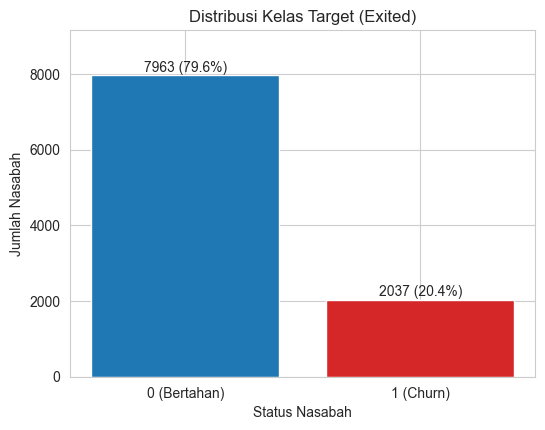

Rasio kelas 0 : kelas 1 = 3.91 : 1


In [7]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

target_counts = df["Exited"].value_counts().sort_index()
labels = ["0 (Bertahan)", "1 (Churn)"]

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(labels, target_counts.values, color=["tab:blue", "tab:red"])
for bar, count in zip(bars, target_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 100,
            f"{count} ({count / len(df) * 100:.1f}%)", ha="center")
ax.set_title("Distribusi Kelas Target (Exited)")
ax.set_xlabel("Status Nasabah")
ax.set_ylabel("Jumlah Nasabah")
ax.set_ylim(0, target_counts.max() * 1.15)
plt.show()

print(f"Rasio kelas 0 : kelas 1 = {target_counts[0] / target_counts[1]:.2f} : 1")


**Interpretasi distribusi target.** Dari 10.000 nasabah, 7.963 (79,63%) bertahan dan 2.037 (20,37%) churn, sehingga rasio kelas 0 : 1 sekitar 3,9 : 1. Dataset ini **imbalanced** (kelas churn sebagai kelas minoritas). Akibatnya accuracy saja bisa menyesatkan: model yang selalu menebak "bertahan" sudah mendapat accuracy sekitar 79,6% tanpa mendeteksi satu pun nasabah churn. Karena itu Precision, Recall, F1, dan ROC-AUC perlu diperhatikan.

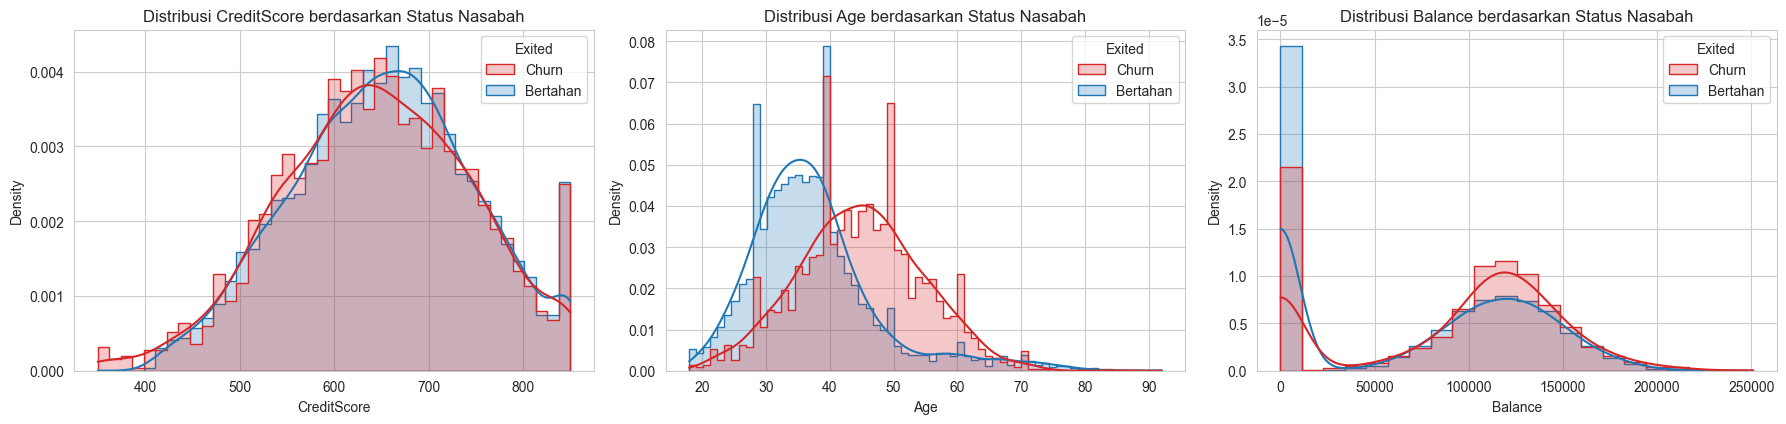

Rata-rata dan median fitur numerik per kelas:


CreditScore          Age         Balance          
              mean median  mean median     mean    median
Exited                                                   
0            651.9  653.0  37.4   36.0  72745.3   92072.7
1            645.4  646.0  44.8   45.0  91108.5  109349.3

In [8]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

status = df["Exited"].map({0: "Bertahan", 1: "Churn"})
palette = {"Bertahan": "tab:blue", "Churn": "tab:red"}

num_cols_eda = ["CreditScore", "Age", "Balance"]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, num_cols_eda):
    sns.histplot(x=df[col], hue=status, kde=True, stat="density", common_norm=False,
                 element="step", palette=palette, ax=ax)
    ax.set_title(f"Distribusi {col} berdasarkan Status Nasabah")
    ax.set_xlabel(col)
    ax.set_ylabel("Density")
plt.tight_layout()
plt.show()

print("Rata-rata dan median fitur numerik per kelas:")
display(df.groupby("Exited")[num_cols_eda].agg(["mean", "median"]).round(1))


**Interpretasi distribusi fitur numerik.**
- **Age**: nasabah yang churn cenderung lebih tua (rata-rata 44,8 tahun vs 37,4 tahun pada nasabah yang bertahan; median 45 vs 36). Distribusi kelas churn bergeser ke kanan.
- **Balance**: rata-rata saldo nasabah churn lebih tinggi (sekitar 91.108 vs 72.745). Terlihat juga lonjakan besar di Balance = 0 (banyak nasabah bersaldo nol).
- **CreditScore**: kedua kelas hampir tumpang tindih (rata-rata 645 vs 652), sehingga fitur ini kurang membedakan churn dibanding Age.

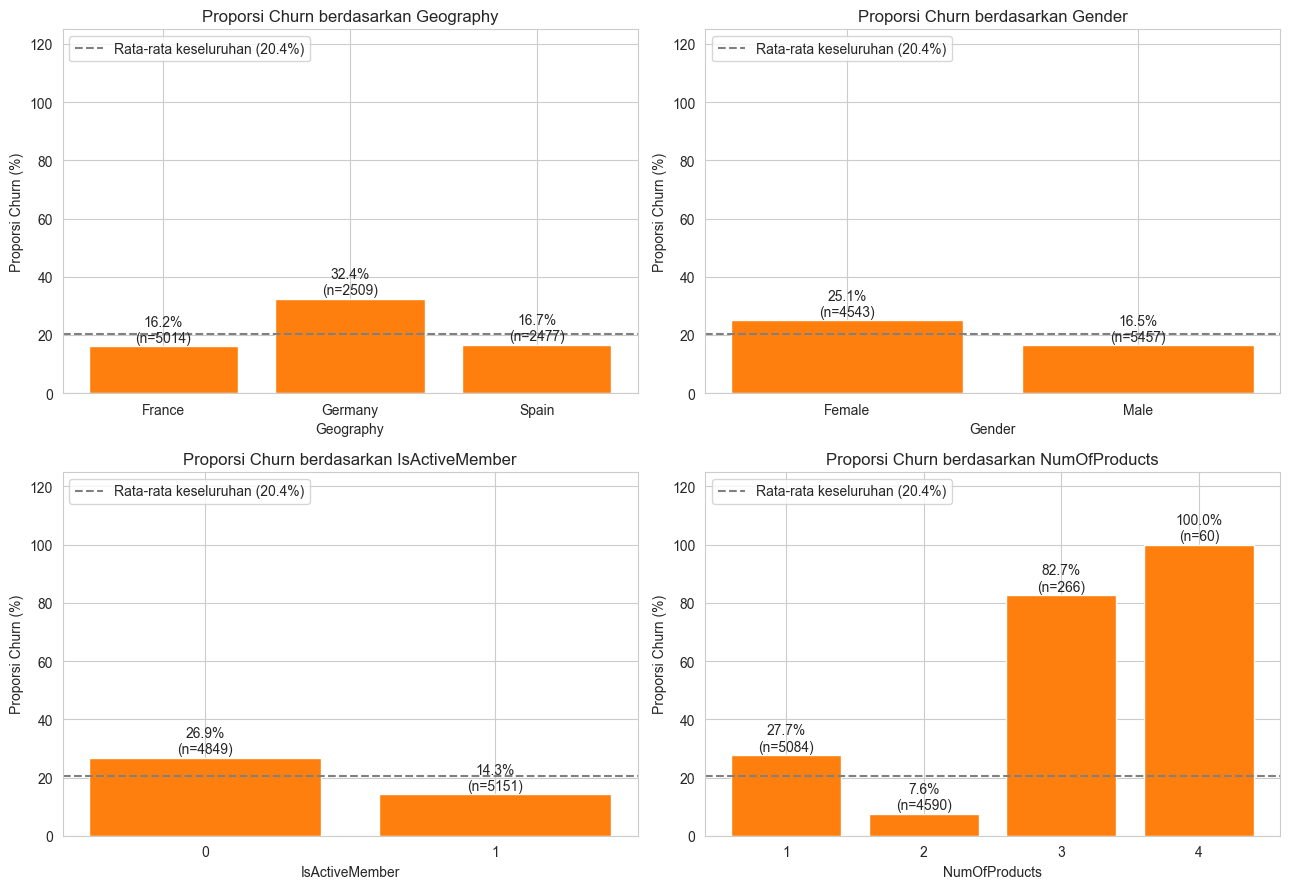

In [9]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

cat_cols_eda = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]
overall_rate = df["Exited"].mean() * 100

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, col in zip(axes.ravel(), cat_cols_eda):
    churn_rate = df.groupby(col)["Exited"].mean() * 100   # persen churn tiap kategori
    group_size = df[col].value_counts()
    bars = ax.bar(churn_rate.index.astype(str), churn_rate.values, color="tab:orange")
    for bar, (cat, rate) in zip(bars, churn_rate.items()):
        ax.text(bar.get_x() + bar.get_width() / 2, rate + 1.5,
                f"{rate:.1f}%\n(n={group_size[cat]})", ha="center")
    ax.axhline(overall_rate, color="gray", linestyle="--", label=f"Rata-rata keseluruhan ({overall_rate:.1f}%)")
    ax.set_title(f"Proporsi Churn berdasarkan {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Proporsi Churn (%)")
    ax.set_ylim(0, 125)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


**Interpretasi proporsi churn per kategori** (rata-rata churn keseluruhan = 20,4%).
- **Geography**: Germany memiliki proporsi churn tertinggi (32,4%), sekitar dua kali France (16,2%) dan Spain (16,7%).
- **Gender**: nasabah perempuan lebih sering churn (25,1%) dibanding laki-laki (16,5%).
- **IsActiveMember**: anggota tidak aktif lebih sering churn (26,9%) dibanding anggota aktif (14,3%).
- **NumOfProducts**: polanya tidak linear. Nasabah dengan 2 produk paling jarang churn (7,6%), dengan 1 produk 27,7%, sedangkan 3 produk (82,7%) dan 4 produk (100%) sangat tinggi. Perlu diingat kelompok 3 dan 4 produk kecil (n = 266 dan n = 60), jadi angkanya kurang stabil.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

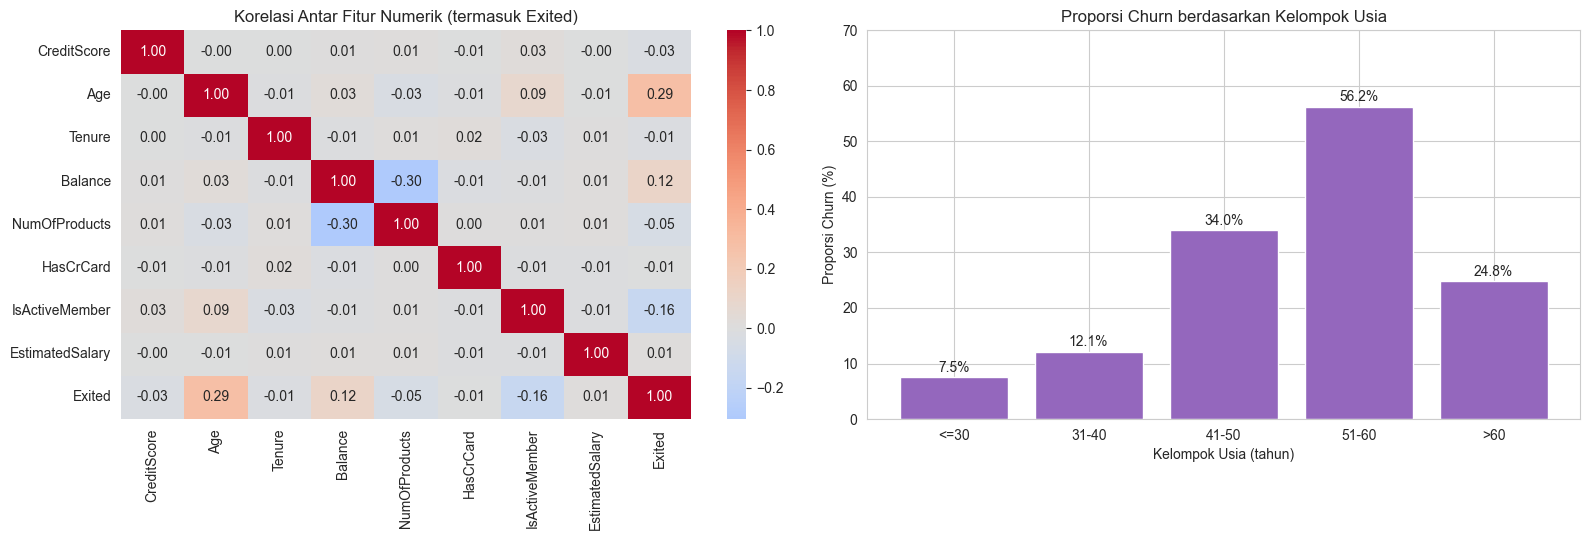

Nasabah dengan Balance = 0 : 36.2% dari seluruh data
Churn pada Balance = 0     : 13.8%
Churn pada Balance > 0     : 24.1%


In [10]:
# EDA tambahan: (1) korelasi fitur numerik dengan Exited, (2) churn per kelompok usia
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

num_for_corr = df.drop(columns=["RowNumber", "CustomerId"]).select_dtypes(include="number")
sns.heatmap(num_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Korelasi Antar Fitur Numerik (termasuk Exited)")

age_group = pd.cut(df["Age"], bins=[0, 30, 40, 50, 60, 100],
                   labels=["<=30", "31-40", "41-50", "51-60", ">60"])
age_rate = df.groupby(age_group, observed=True)["Exited"].mean() * 100
bars = axes[1].bar(age_rate.index.astype(str), age_rate.values, color="tab:purple")
for bar, rate in zip(bars, age_rate.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, rate + 1, f"{rate:.1f}%", ha="center")
axes[1].set_title("Proporsi Churn berdasarkan Kelompok Usia")
axes[1].set_xlabel("Kelompok Usia (tahun)")
axes[1].set_ylabel("Proporsi Churn (%)")
axes[1].set_ylim(0, 70)
plt.tight_layout()
plt.show()

# Nasabah dengan saldo 0
zero_bal = df["Balance"] == 0
print(f"Nasabah dengan Balance = 0 : {zero_bal.mean() * 100:.1f}% dari seluruh data")
print(f"Churn pada Balance = 0     : {df.loc[zero_bal, 'Exited'].mean() * 100:.1f}%")
print(f"Churn pada Balance > 0     : {df.loc[~zero_bal, 'Exited'].mean() * 100:.1f}%")


**Interpretasi EDA tambahan.**
- Korelasi linear terhadap `Exited` terbesar ada pada **Age** (+0,29), diikuti **IsActiveMember** (-0,16) dan **Balance** (+0,12). Fitur lain (CreditScore, Tenure, HasCrCard, EstimatedSalary) berkorelasi sangat lemah (|r| < 0,05). Korelasi menunjukkan hubungan, bukan sebab-akibat.
- Proporsi churn naik tajam seiring usia: 7,5% (<=30), 12,1% (31-40), 34,0% (41-50), dan 56,2% (51-60), lalu turun menjadi 24,8% pada kelompok >60 tahun. Jadi hubungan Age dengan churn tidak sepenuhnya linear.
- Sebanyak 36,2% nasabah memiliki Balance = 0. Churn pada kelompok ini 13,8%, lebih rendah dibanding Balance > 0 (24,1%).
- Tidak ada missing value, tidak ada baris duplikat, dan CustomerId unik, sehingga tidak diperlukan imputasi atau penghapusan duplikat.
- Fitur dengan hubungan non-linear (misalnya NumOfProducts dan Age) adalah alasan mengapa ANN berpotensi lebih baik daripada Logistic Regression, namun hal ini harus dibuktikan lewat hasil evaluasi.

# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [11]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# RowNumber : hanya nomor urut baris, tidak membawa informasi tentang nasabah.
# CustomerId: ID unik tiap nasabah (identifier), tidak punya makna prediktif dan bisa
#             membuat model "menghafal" data.
# Surname   : nama belakang, hampir unik dan bukan karakteristik perilaku nasabah.
df_clean = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print("Kolom setelah di-drop:", list(df_clean.columns))


Kolom setelah di-drop: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [12]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

# Encoding Gender menjadi 0/1. Ini aturan tetap (bukan hasil "belajar" dari data),
# jadi aman dilakukan sebelum split dan tidak menyebabkan data leakage.
df_clean["Gender"] = df_clean["Gender"].map({"Female": 0, "Male": 1})

# Pisahkan fitur (X) dan target (y)
X = df_clean.drop(columns="Exited")
y = df_clean["Exited"]

# Split 70 : 15 : 15 dengan stratify.
# Langkah 1: 70% train, 30% sisanya (temp)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42)
# Langkah 2: sisa 30% dibagi dua sama besar -> 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

for name, labels_ in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:10s}: {len(labels_):5d} data | proporsi churn = {labels_.mean() * 100:.2f}%")


Train     :  7000 data | proporsi churn = 20.37%
Validation:  1500 data | proporsi churn = 20.40%
Test      :  1500 data | proporsi churn = 20.33%


In [13]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

onehot_cols = ["Geography"]                                   # kategorikal nominal -> One-Hot
numeric_cols = ["CreditScore", "Age", "Tenure", "Balance",
                "NumOfProducts", "EstimatedSalary"]            # numerik -> StandardScaler
binary_cols = ["Gender", "HasCrCard", "IsActiveMember"]       # sudah 0/1 -> dibiarkan apa adanya

preprocessor = ColumnTransformer(transformers=[
    ("geo", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), onehot_cols),
    ("num", StandardScaler(), numeric_cols),
    ("bin", "passthrough", binary_cols),
])

# fit HANYA pada train set, lalu transform train/validation/test (mencegah data leakage)
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print("Fitur setelah preprocessing:", list(feature_names))
print("Shape train / val / test   :", X_train_proc.shape, X_val_proc.shape, X_test_proc.shape)
print("Ada NaN?                   :", np.isnan(X_train_proc).any() or np.isnan(X_val_proc).any() or np.isnan(X_test_proc).any())

# Cek: fitur numerik pada train set harus punya mean ~0 dan std ~1
scaled_part = pd.DataFrame(X_train_proc, columns=feature_names).filter(like="num__")
print("\nMean & std fitur numerik (train set):")
display(scaled_part.agg(["mean", "std"]).round(3))


Fitur setelah preprocessing: ['geo__Geography_France', 'geo__Geography_Germany', 'geo__Geography_Spain', 'num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__EstimatedSalary', 'bin__Gender', 'bin__HasCrCard', 'bin__IsActiveMember']
Shape train / val / test   : (7000, 12) (1500, 12) (1500, 12)
Ada NaN?                   : False

Mean & std fitur numerik (train set):


,num__CreditScore,num__Age,num__Tenure,num__Balance,num__NumOfProducts,num__EstimatedSalary
mean,0.0,0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


In [14]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

BATCH_SIZE = 64

def to_tensor_X(array):
    return torch.tensor(array, dtype=torch.float32)

def to_tensor_y(series):
    # bentuk (N, 1) agar sama dengan bentuk output model
    return torch.tensor(np.asarray(series), dtype=torch.float32).view(-1, 1)

X_train_t, y_train_t = to_tensor_X(X_train_proc), to_tensor_y(y_train)
X_val_t,   y_val_t   = to_tensor_X(X_val_proc),   to_tensor_y(y_val)
X_test_t,  y_test_t  = to_tensor_X(X_test_proc),  to_tensor_y(y_test)

print("X_train:", X_train_t.shape, X_train_t.dtype, "| y_train:", y_train_t.shape, y_train_t.dtype)
print("X_val  :", X_val_t.shape, "| y_val:", y_val_t.shape)
print("X_test :", X_test_t.shape, "| y_test:", y_test_t.shape)

# DataLoader hanya untuk train set (shuffle=True). Validation & test cukup dievaluasi
# sekaligus (satu tensor penuh) karena datanya kecil, jadi DataLoader tidak diperlukan.
g = torch.Generator()
g.manual_seed(42)
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                          batch_size=BATCH_SIZE, shuffle=True, generator=g)

input_dim = X_train_t.shape[1]
print("Jumlah fitur input (input_dim):", input_dim)


X_train: torch.Size([7000, 12]) torch.float32 | y_train: torch.Size([7000, 1]) torch.float32
X_val  : torch.Size([1500, 12]) | y_val: torch.Size([1500, 1])
X_test : torch.Size([1500, 12]) | y_test: torch.Size([1500, 1])
Jumlah fitur input (input_dim): 12


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [15]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_proc, y_train)

# Prediksi test set: label dan probabilitas kelas 1
y_pred_lr = log_reg.predict(X_test_proc)
y_prob_lr = log_reg.predict_proba(X_test_proc)[:, 1]

print("Logistic Regression - hasil pada test set")
print(classification_report(y_test, y_pred_lr, target_names=["Bertahan (0)", "Churn (1)"], digits=4))


Logistic Regression - hasil pada test set
              precision    recall  f1-score   support

Bertahan (0)     0.8269    0.9715    0.8934      1195
   Churn (1)     0.6458    0.2033    0.3092       305

    accuracy                         0.8153      1500
   macro avg     0.7364    0.5874    0.6013      1500
weighted avg     0.7901    0.8153    0.7746      1500



## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [16]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

class SimpleANN(nn.Module):
    """ANN 1 hidden layer: Input -> Linear(16) -> ReLU -> Linear(1)"""
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)      # output berupa logit (tanpa Sigmoid)
        )

    def forward(self, x):
        return self.net(x)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(42)             # seed sebelum membuat model -> bobot awal reprodusibel
model_simple = SimpleANN(input_dim)
print(model_simple)
print("Jumlah parameter:", count_parameters(model_simple))


SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 225


In [17]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

# Hyperparameter (sama untuk semua ANN agar adil dibandingkan)
LEARNING_RATE = 0.001
EPOCHS = 50
# (BATCH_SIZE = 64 sudah diatur pada bagian DataLoader)

def evaluate_loss_acc(model, X, y, criterion):
    """Hitung loss dan accuracy pada satu set data (tanpa gradien, mode eval)."""
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = criterion(logits, y).item()
        preds = (torch.sigmoid(logits) >= 0.5).float()   # sigmoid hanya untuk prediksi
        acc = (preds == y).float().mean().item()
    return loss, acc

def train_model(model, criterion, learning_rate=LEARNING_RATE, epochs=EPOCHS):
    """Training loop yang dipakai ulang untuk ketiga ANN. Mengembalikan history."""
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()                                   # aktifkan mode training (Dropout aktif)
        for X_batch, y_batch in train_loader:
            logits = model(X_batch)                     # 1. forward
            loss = criterion(logits, y_batch)           # 2. hitung loss
            optimizer.zero_grad()                       # 3. kosongkan gradien lama
            loss.backward()                             # 4. backpropagation
            optimizer.step()                            # 5. update bobot

        # Akhir epoch: evaluasi pada seluruh train set dan validation set
        train_loss, train_acc = evaluate_loss_acc(model, X_train_t, y_train_t, criterion)
        val_loss, val_acc = evaluate_loss_acc(model, X_val_t, y_val_t, criterion)
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch + 1:3d}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.4f} "
                  f"| val loss {val_loss:.4f} acc {val_acc:.4f}")
    return history

# Latih ANN sederhana
criterion = nn.BCEWithLogitsLoss()
history_simple = train_model(model_simple, criterion)


Epoch   1/50 | train loss 0.5002 acc 0.7963 | val loss 0.5002 acc 0.7960
Epoch  10/50 | train loss 0.3797 acc 0.8426 | val loss 0.3661 acc 0.8453
Epoch  20/50 | train loss 0.3542 acc 0.8536 | val loss 0.3384 acc 0.8567
Epoch  30/50 | train loss 0.3481 acc 0.8560 | val loss 0.3321 acc 0.8613
Epoch  40/50 | train loss 0.3447 acc 0.8574 | val loss 0.3298 acc 0.8580
Epoch  50/50 | train loss 0.3428 acc 0.8597 | val loss 0.3291 acc 0.8580


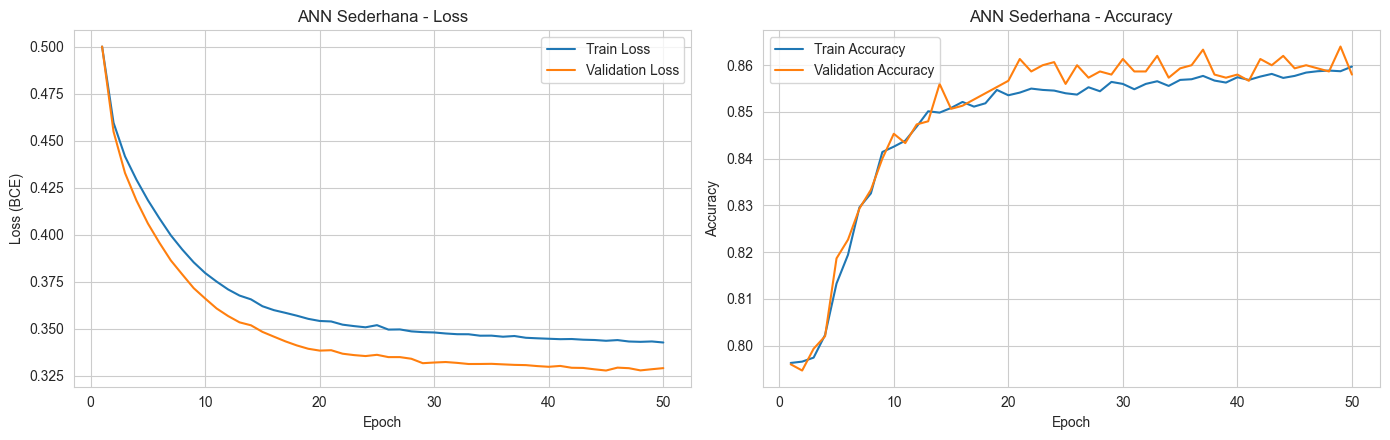

In [18]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

def plot_learning_curve(history, title):
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

    axes[0].plot(epochs_range, history["train_loss"], label="Train Loss")
    axes[0].plot(epochs_range, history["val_loss"], label="Validation Loss")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss (BCE)")
    axes[0].legend()

    axes[1].plot(epochs_range, history["train_acc"], label="Train Accuracy")
    axes[1].plot(epochs_range, history["val_acc"], label="Validation Accuracy")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_learning_curve(history_simple, "ANN Sederhana")


In [19]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

def predict_ann(model, X):
    """Return (label, probabilitas kelas 1) dalam bentuk numpy array."""
    model.eval()
    with torch.no_grad():
        logits = model(X)
        probs = torch.sigmoid(logits).cpu().numpy().ravel()   # logit -> probabilitas
    labels = (probs >= 0.5).astype(int)                       # threshold 0.5
    return labels, probs

y_pred_simple, y_prob_simple = predict_ann(model_simple, X_test_t)
print("Contoh 5 probabilitas :", np.round(y_prob_simple[:5], 3))
print("Contoh 5 label        :", y_pred_simple[:5])


Contoh 5 probabilitas : [0.202 0.018 0.069 0.07  0.237]
Contoh 5 label        : [0 0 0 0 0]


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [20]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    """ANN 2 hidden layer + Dropout: Input -> 64 -> ReLU -> Dropout -> 32 -> ReLU -> Dropout -> 1"""
    def __init__(self, input_dim, dropout_p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout_p),    # aktif hanya saat model.train()
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout_p),
            nn.Linear(32, 1)          # output berupa logit
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
model_deep = DeepANN(input_dim)
print(model_deep)
print("Jumlah parameter:", count_parameters(model_deep))


DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Jumlah parameter: 2945


Epoch   1/50 | train loss 0.4491 acc 0.7963 | val loss 0.4388 acc 0.7960
Epoch  10/50 | train loss 0.3500 acc 0.8547 | val loss 0.3407 acc 0.8520
Epoch  20/50 | train loss 0.3376 acc 0.8619 | val loss 0.3278 acc 0.8647
Epoch  30/50 | train loss 0.3313 acc 0.8644 | val loss 0.3237 acc 0.8653
Epoch  40/50 | train loss 0.3262 acc 0.8667 | val loss 0.3224 acc 0.8660
Epoch  50/50 | train loss 0.3224 acc 0.8654 | val loss 0.3183 acc 0.8687


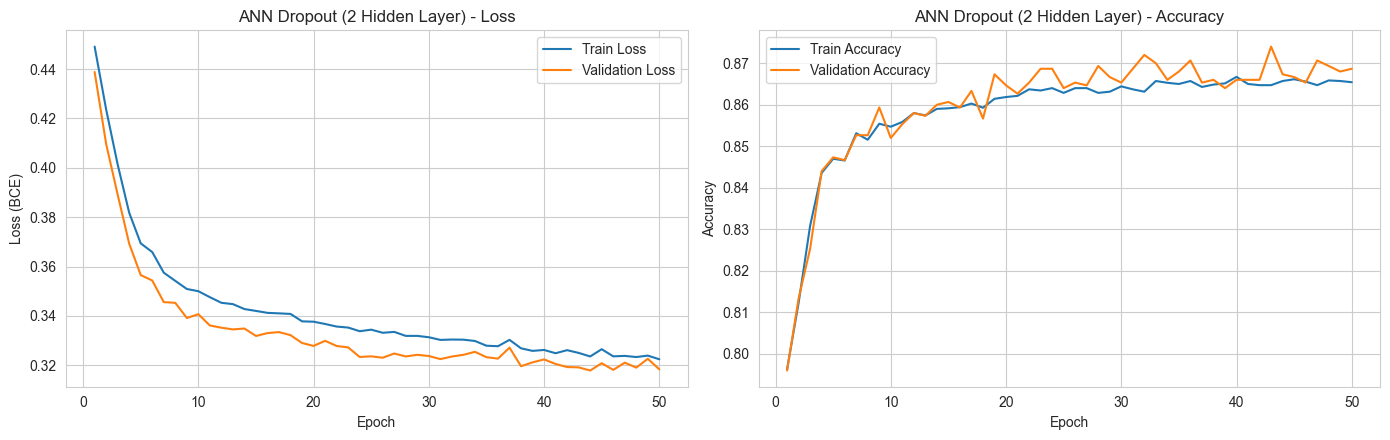

In [21]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

history_deep = train_model(model_deep, nn.BCEWithLogitsLoss())
plot_learning_curve(history_deep, "ANN Dropout (2 Hidden Layer)")


In [22]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_pred_deep, y_prob_deep = predict_ann(model_deep, X_test_t)
print("Contoh 5 probabilitas :", np.round(y_prob_deep[:5], 3))
print("Contoh 5 label        :", y_pred_deep[:5])


Contoh 5 probabilitas : [0.152 0.017 0.043 0.061 0.204]
Contoh 5 label        : [0 0 0 0 0]


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [23]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# Pilih arsitektur terbaik dari 3.2 / 3.3 berdasarkan VALIDATION set (bukan test set).
# Kriteria: validation loss pada epoch terakhir (model yang dipakai untuk prediksi).
val_loss_simple = history_simple["val_loss"][-1]
val_loss_deep = history_deep["val_loss"][-1]
print(f"Val loss akhir - ANN Sederhana: {val_loss_simple:.4f} | ANN Dropout: {val_loss_deep:.4f}")
print(f"Val acc  akhir - ANN Sederhana: {history_simple['val_acc'][-1]:.4f} | ANN Dropout: {history_deep['val_acc'][-1]:.4f}")

use_simple = val_loss_simple <= val_loss_deep
chosen_arch = "ANN Sederhana" if use_simple else "ANN Dropout"
print("Arsitektur terpilih untuk class weight:", chosen_arch)

# pos_weight = jumlah kelas 0 / jumlah kelas 1 (dihitung dari TRAIN set)
n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())
pos_weight = n_neg / n_pos
print(f"Train set: kelas 0 = {n_neg}, kelas 1 = {n_pos}, pos_weight = {pos_weight:.4f}")

# Buat ulang model dari awal (bobot baru)
torch.manual_seed(42)
model_cw = SimpleANN(input_dim) if use_simple else DeepANN(input_dim)
print(model_cw)
print("Jumlah parameter:", count_parameters(model_cw))

criterion_cw = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], dtype=torch.float32))
history_cw = train_model(model_cw, criterion_cw)


Val loss akhir - ANN Sederhana: 0.3291 | ANN Dropout: 0.3183
Val acc  akhir - ANN Sederhana: 0.8580 | ANN Dropout: 0.8687
Arsitektur terpilih untuk class weight: ANN Dropout
Train set: kelas 0 = 5574, kelas 1 = 1426, pos_weight = 3.9088
DeepANN(
  (net): Sequential(
    (0): Linear(in_features=12, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Jumlah parameter: 2945
Epoch   1/50 | train loss 0.9166 acc 0.7336 | val loss 0.8814 acc 0.7480
Epoch  10/50 | train loss 0.7499 acc 0.7693 | val loss 0.7284 acc 0.7620
Epoch  20/50 | train loss 0.7212 acc 0.7880 | val loss 0.7051 acc 0.7753
Epoch  30/50 | train loss 0.7050 acc 0.8053 | val loss 0.6992 acc 0.7960
Epoch  40/50 | train loss 0.6948 acc 0.7969 | val loss 0.6956 acc 0.7827
Epoch  50/50 | train loss 0.6865 acc 0.7969 | val 

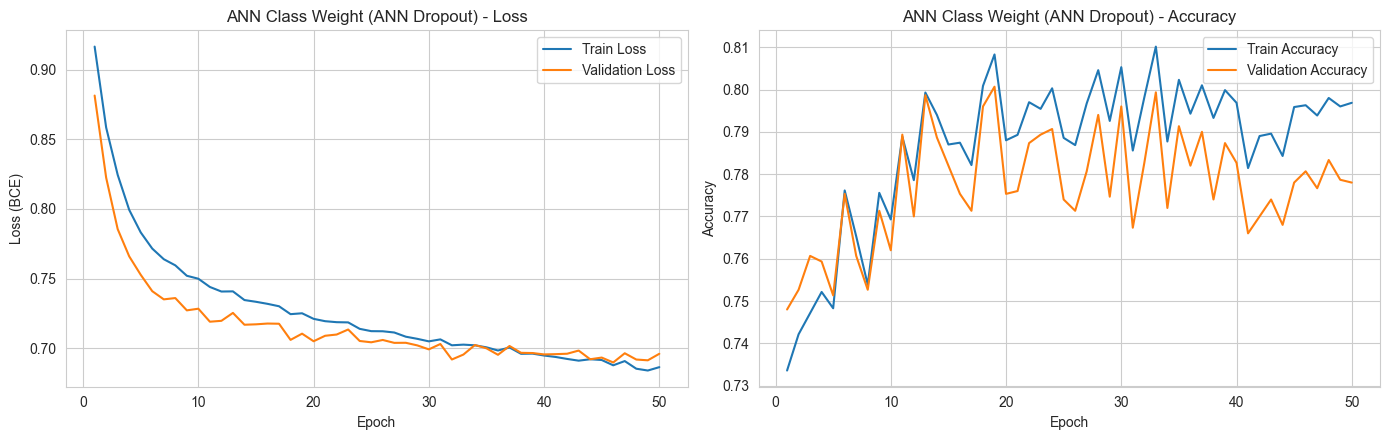

Contoh 5 probabilitas : [0.497 0.095 0.112 0.217 0.532]
Contoh 5 label        : [0 0 0 0 1]


In [24]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

# Catatan: loss pada model ini dihitung dengan pos_weight, jadi nilainya tidak bisa
# dibandingkan langsung dengan loss model tanpa class weight (skalanya berbeda).
plot_learning_curve(history_cw, f"ANN Class Weight ({chosen_arch})")

y_pred_cw, y_prob_cw = predict_ann(model_cw, X_test_t)
print("Contoh 5 probabilitas :", np.round(y_prob_cw[:5], 3))
print("Contoh 5 label        :", y_pred_cw[:5])


# 4. Evaluasi Model

In [25]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

# Kumpulkan hasil prediksi test set semua model: nama -> (label prediksi, probabilitas kelas 1)
results = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "ANN Sederhana":       (y_pred_simple, y_prob_simple),
    "ANN Dropout":         (y_pred_deep, y_prob_deep),
    "ANN Class Weight":    (y_pred_cw, y_prob_cw),
}
y_true = np.asarray(y_test)

rows = []
for name, (pred, prob) in results.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision (churn)": precision_score(y_true, pred, zero_division=0),
        "Recall (churn)": recall_score(y_true, pred, zero_division=0),
        "F1-Score (churn)": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob),
    })

metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
print("Perbandingan model pada TEST set (Precision/Recall/F1 untuk kelas churn = 1):")
display(metrics_df)


Perbandingan model pada TEST set (Precision/Recall/F1 untuk kelas churn = 1):


,Accuracy,Precision (churn),Recall (churn),F1-Score (churn),ROC-AUC
Model,,,,,
Logistic Regression,0.8153,0.6458,0.2033,0.3092,0.7913
ANN Sederhana,0.8607,0.7697,0.4492,0.5673,0.8672
ANN Dropout,0.8660,0.8095,0.4459,0.5751,0.8651
ANN Class Weight,0.7807,0.4759,0.7770,0.5903,0.8608


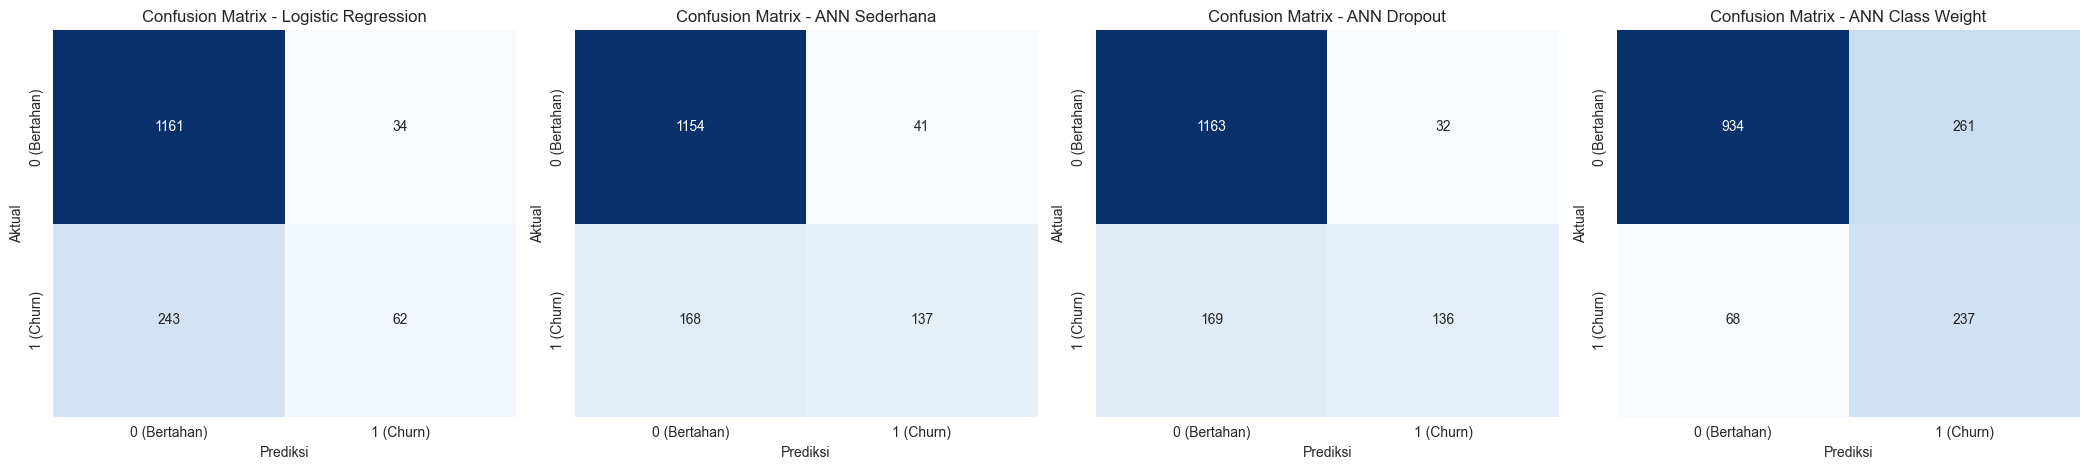

In [26]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
for ax, (name, (pred, prob)) in zip(axes, results.items()):
    cm = confusion_matrix(y_true, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["0 (Bertahan)", "1 (Churn)"],
                yticklabels=["0 (Bertahan)", "1 (Churn)"])
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Aktual")
plt.tight_layout()
plt.show()


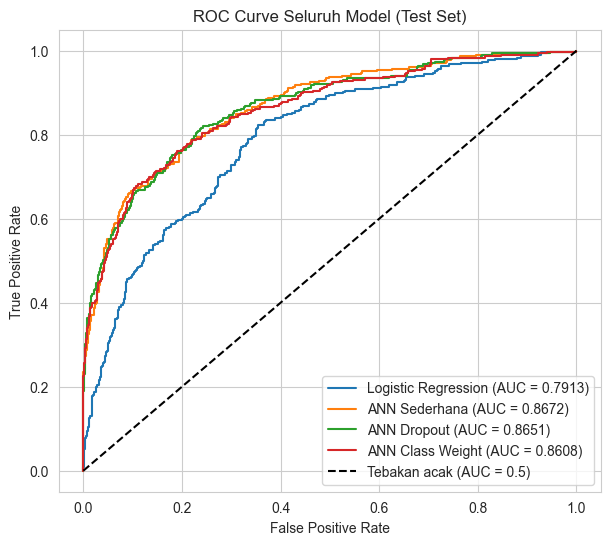

In [27]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(7, 6))
for name, (pred, prob) in results.items():
    fpr, tpr, _ = roc_curve(y_true, prob)
    auc = roc_auc_score(y_true, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="Tebakan acak (AUC = 0.5)")
plt.title("ROC Curve Seluruh Model (Test Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()


In [28]:
# Ringkasan otomatis untuk membantu analisis (semua angka dihitung dari hasil eksperimen di atas)
print("=== Model terbaik per metrik (test set) ===")
for metric in metrics_df.columns:
    print(f"{metric:20s}: {metrics_df[metric].idxmax():20s} ({metrics_df[metric].max():.4f})")

print("\n=== Indikator overfitting/underfitting dari learning curve ===")
histories = {"ANN Sederhana": history_simple, "ANN Dropout": history_deep, "ANN Class Weight": history_cw}
summary = []
for name, h in histories.items():
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    summary.append({
        "Model": name,
        "Train loss akhir": h["train_loss"][-1],
        "Val loss akhir": h["val_loss"][-1],
        "Gap (val - train) loss": h["val_loss"][-1] - h["train_loss"][-1],
        "Val loss terendah": min(h["val_loss"]),
        "Epoch val loss terendah": best_epoch,
        "Train acc akhir": h["train_acc"][-1],
        "Val acc akhir": h["val_acc"][-1],
    })
display(pd.DataFrame(summary).set_index("Model").round(4))
print("Catatan: jika epoch val loss terendah jauh lebih awal dari epoch terakhir dan val loss naik "
      "setelahnya, itu tanda overfitting. Jika train loss dan val loss sama-sama masih tinggi/turun, "
      "kemungkinan underfitting.")


=== Model terbaik per metrik (test set) ===
Accuracy            : ANN Dropout          (0.8660)
Precision (churn)   : ANN Dropout          (0.8095)
Recall (churn)      : ANN Class Weight     (0.7770)
F1-Score (churn)    : ANN Class Weight     (0.5903)
ROC-AUC             : ANN Sederhana        (0.8672)

=== Indikator overfitting/underfitting dari learning curve ===


,Train loss akhir,Val loss akhir,Gap (val - train) loss,Val loss terendah,Epoch val loss terendah,Train acc akhir,Val acc akhir
Model,,,,,,,
ANN Sederhana,0.3428,0.3291,-0.0136,0.3278,45,0.8597,0.8580
ANN Dropout,0.3224,0.3183,-0.0041,0.3179,44,0.8654,0.8687
ANN Class Weight,0.6865,0.6961,0.0096,0.6898,46,0.7969,0.7780


Catatan: jika epoch val loss terendah jauh lebih awal dari epoch terakhir dan val loss naik setelahnya, itu tanda overfitting. Jika train loss dan val loss sama-sama masih tinggi/turun, kemungkinan underfitting.


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Logistic Regression dan setiap konfigurasi ANN berdasarkan hasil evaluasi. Bahas pula bentuk learning curve masing-masing model (overfitting/underfitting), pengaruh penambahan layer dan Dropout, serta pengaruh class weight terhadap precision dan recall kelas churn. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**1. Karakteristik dataset berdasarkan EDA**

Dataset yang digunakan terdiri dari 10.000 data nasabah dengan 14 kolom. Setelah kolom identitas (RowNumber, CustomerId, dan Surname) dihapus, terdapat 10 fitur yang digunakan untuk memprediksi status nasabah (Exited). Berdasarkan pemeriksaan awal, tidak ditemukan missing value maupun baris duplikat. Oleh karena itu, data tidak memerlukan proses imputasi atau penghapusan data duplikat.

Hasil EDA menunjukkan bahwa jumlah nasabah yang bertahan adalah 7.963 orang (79,63%), sedangkan nasabah yang churn berjumlah 2.037 orang (20,37%). Beberapa karakteristik yang memiliki hubungan dengan churn adalah sebagai berikut.
- Usia (Age): nasabah yang churn memiliki rata-rata usia 44,8 tahun, sedangkan nasabah yang bertahan memiliki rata-rata 37,4 tahun. Proporsi churn juga meningkat pada kelompok usia 41–50 tahun (34,0%) dan 51–60 tahun (56,2%). Hal ini menunjukkan bahwa usia merupakan salah satu fitur yang cukup membedakan kedua kelas, meskipun hubungannya tidak sepenuhnya linear.
- Geography: nasabah yang berasal dari Germany memiliki tingkat churn tertinggi, yaitu 32,4%. Angka ini lebih tinggi dibandingkan France (16,2%) dan Spain (16,7%).
- Gender dan aktivitas nasabah: tingkat churn pada nasabah perempuan sebesar 25,1%, lebih tinggi daripada laki-laki (16,5%). Nasabah yang tidak aktif juga memiliki tingkat churn lebih tinggi (26,9%) dibandingkan nasabah aktif (14,3%).
- Jumlah produk (NumOfProducts): tingkat churn berbeda cukup jauh antarjumlah produk. Nasabah dengan 2 produk memiliki tingkat churn 7,6%, sedangkan nasabah dengan 1 produk sebesar 27,7%. Tingkat churn pada kelompok 3 dan 4 produk sangat tinggi, masing-masing 82,7% dan 100%. Namun, jumlah data pada dua kelompok terakhir relatif sedikit (266 dan 60 nasabah), sehingga hasil tersebut perlu ditafsirkan secara hati-hati.
- Saldo (Balance): rata-rata saldo nasabah churn sekitar 91.108, lebih tinggi daripada nasabah yang bertahan, yaitu sekitar 72.745. Selain itu, tingkat churn pada nasabah dengan saldo di atas nol sebesar 24,1%, sedangkan pada nasabah dengan saldo nol sebesar 13,8%.
- Fitur lainnya: CreditScore, Tenure, HasCrCard, dan EstimatedSalary menunjukkan hubungan yang relatif lemah dengan status churn pada pemeriksaan EDA ini. Korelasi linear terbesar terhadap Exited dimiliki oleh Age (+0,29), kemudian IsActiveMember (-0,16) dan Balance (+0,12). Korelasi ini menunjukkan hubungan, bukan hubungan sebab-akibat.
Dari hasil tersebut, dapat dilihat bahwa karakteristik nasabah yang churn tidak selalu dapat dipisahkan menggunakan satu batas linear sederhana. Pola seperti hubungan usia dan jumlah produk menjadi salah satu alasan untuk menguji ANN yang dapat mempelajari hubungan yang lebih kompleks.

**2. Pengaruh ketidakseimbangan kelas (class imbalance)**

Dataset memiliki ketidakseimbangan kelas karena nasabah yang bertahan mencapai 79,63%, sedangkan nasabah yang churn hanya 20,37%. Rasio kelas bertahan terhadap churn sekitar 3,91 : 1. Kondisi ini perlu diperhatikan karena model yang selalu memprediksi nasabah bertahan saja sudah dapat memperoleh accuracy sekitar 79,6% pada data test.

Oleh sebab itu, accuracy tidak cukup digunakan sebagai satu-satunya ukuran keberhasilan model. Recall dan F1-Score untuk kelas churn juga penting karena tujuan eksperimen adalah mendeteksi nasabah yang berpotensi meninggalkan bank. Model dengan accuracy tinggi belum tentu berhasil menemukan banyak nasabah churn.

**3. Perbandingan Logistic Regression dan ANN**

Berdasarkan hasil evaluasi pada test set, Logistic Regression memperoleh accuracy sebesar 81,53%, precision churn 64,58%, recall churn 20,33%, F1-Score 30,92%, dan ROC-AUC 0,7913. Recall yang rendah menunjukkan bahwa model ini hanya berhasil mendeteksi sebagian kecil nasabah yang benar-benar churn. Dari 305 nasabah churn pada test set, model hanya memprediksi 62 nasabah sebagai churn dan melewatkan 243 nasabah lainnya.

ANN Sederhana memberikan peningkatan dibandingkan Logistic Regression. Accuracy meningkat menjadi 86,07%, recall churn menjadi 44,92%, F1-Score menjadi 56,73%, dan ROC-AUC menjadi 0,8672. Hasil tersebut menunjukkan bahwa ANN Sederhana lebih baik dalam membedakan nasabah bertahan dan churn berdasarkan probabilitas prediksinya, sekaligus lebih banyak mendeteksi kelas churn.

ANN Dropout memperoleh accuracy 86,60%, precision 80,95%, recall 44,59%, F1-Score 57,51%, dan ROC-AUC 0,8651. Dibandingkan ANN Sederhana, model ini memiliki accuracy dan precision yang sedikit lebih tinggi, sedangkan recall dan ROC-AUC sedikit lebih rendah. Dengan demikian, model ini lebih tepat ketika ketepatan prediksi churn menjadi perhatian, tetapi peningkatannya terhadap ANN Sederhana relatif kecil.

Secara keseluruhan, kedua ANN tanpa class weight memberikan hasil yang lebih baik daripada Logistic Regression pada sebagian besar metrik, terutama recall, F1-Score, dan ROC-AUC. Hasil ini menunjukkan bahwa ANN mampu mempelajari pola pada data dengan lebih baik pada eksperimen ini. Meskipun demikian, Logistic Regression tetap dapat digunakan sebagai baseline yang lebih sederhana.

**4. Pengaruh penambahan hidden layer dan Dropout**

ANN Sederhana menggunakan satu hidden layer dengan 16 neuron dan memiliki 225 parameter. Sementara itu, ANN Dropout menggunakan dua hidden layer dengan masing-masing 64 dan 32 neuron serta Dropout sebesar 0,3, sehingga memiliki 2.945 parameter.

Penambahan kompleksitas tersebut menghasilkan kenaikan accuracy dari 86,07% menjadi 86,60%, precision dari 76,97% menjadi 80,95%, dan F1-Score dari 56,73% menjadi 57,51%. Namun, recall sedikit turun dari 44,92% menjadi 44,59% dan ROC-AUC turun dari 0,8672 menjadi 0,8651. Dengan kata lain, ANN Dropout memberikan peningkatan pada beberapa metrik, tetapi tidak unggul pada seluruh metrik.

Jumlah parameter ANN Dropout jauh lebih besar, tetapi peningkatan performanya relatif kecil. Oleh karena itu, penambahan hidden layer tidak selalu menghasilkan peningkatan yang sebanding dengan kompleksitas model. Selain itu, pada eksperimen ini arsitektur yang lebih dalam sekaligus menggunakan Dropout, sehingga pengaruh penambahan layer dan pengaruh Dropout belum dapat dipisahkan sepenuhnya. Untuk mengetahui pengaruh Dropout secara lebih khusus, diperlukan percobaan tambahan dengan arsitektur yang sama, tetapi satu model menggunakan Dropout dan model lainnya tanpa Dropout.

**5. Analisis learning curve dan overfitting/underfitting**

Pada ANN Sederhana, train loss dan validation loss sama-sama mengalami penurunan pada sebagian besar epoch, kemudian mulai stabil. Validation loss terendah sebesar 0,3278 diperoleh pada epoch ke-45, sedangkan pada epoch ke-50 nilainya menjadi 0,3291. Pada akhir training, train loss sebesar 0,3428 dan validation loss sebesar 0,3291. Jarak kedua kurva relatif kecil dan tidak terlihat kenaikan validation loss yang tajam. Dengan demikian, tidak terdapat indikasi overfitting yang kuat pada ANN Sederhana.

Pada ANN Dropout, train loss dan validation loss juga menurun dan bergerak berdekatan. Validation loss terendah sebesar 0,3179 terjadi pada epoch ke-44, kemudian sedikit meningkat menjadi 0,3183 pada epoch ke-50. Train loss akhir sebesar 0,3224 dan validation loss akhir sebesar 0,3183. Jarak kedua loss tersebut lebih kecil dibandingkan ANN Sederhana. Hal ini menunjukkan bahwa kurva training dan validation pada ANN Dropout lebih berdekatan dalam eksperimen ini. Tidak terlihat tanda overfitting yang kuat, karena kenaikan validation loss setelah titik terendah hanya sedikit.

Pada ANN Class Weight, validation loss terendah sebesar 0,6898 terjadi pada epoch ke-46 dan meningkat menjadi 0,6961 pada epoch ke-50. Train loss akhirnya sebesar 0,6865, sedangkan validation loss sebesar 0,6961. Kurva accuracy model ini terlihat lebih berfluktuasi dibandingkan dua model sebelumnya. Hal tersebut menunjukkan bahwa proses pembelajaran model dengan class weight lebih tidak stabil pada eksperimen ini. Meskipun ada sedikit kenaikan validation loss menjelang akhir training, titik terendahnya masih berada dekat epoch terakhir sehingga belum menunjukkan overfitting yang berat.

Loss ANN Class Weight tidak dapat dibandingkan langsung dengan loss dua ANN sebelumnya karena fungsi loss-nya menggunakan pos_weight. Perbedaan skala loss tersebut berasal dari pembobotan kelas pada fungsi loss, sehingga penilaian model lebih tepat dilakukan dengan memperhatikan metrik evaluasi dan kurva masing-masing model.

Secara umum, ketiga model ANN tidak menunjukkan gejala overfitting yang berat. Validation loss terendah seluruh model juga terjadi mendekati epoch terakhir. Namun, hasil ini tidak berarti model sudah optimal karena hyperparameter dan jumlah epoch belum diuji lebih lanjut.

**6. Pengaruh class weight terhadap precision dan recall churn**

Pada eksperimen ini, nilai pos_weight dihitung dari perbandingan jumlah kelas 0 dan kelas 1 pada train set, yaitu 5.574 dibagi 1.426, sehingga diperoleh nilai 3,9088. Dengan pembobotan ini, kesalahan prediksi pada nasabah churn mendapat penalti lebih besar saat training.

Perbandingan yang paling sesuai adalah ANN Dropout tanpa class weight dengan ANN Class Weight, karena ANN Class Weight menggunakan arsitektur ANN Dropout yang dipilih berdasarkan validation loss. Setelah class weight diterapkan, recall churn meningkat dari 44,59% menjadi 77,70%. Artinya, model dapat mendeteksi lebih banyak nasabah yang benar-benar churn. Jumlah false negative pada confusion matrix juga turun dari 169 menjadi 68.

Namun, peningkatan recall tersebut disertai penurunan precision dari 80,95% menjadi 47,59%. Jumlah false positive meningkat dari 32 menjadi 291, yang berarti semakin banyak nasabah yang sebenarnya bertahan tetapi diprediksi akan churn. Accuracy juga turun dari 86,60% menjadi 78,07%. Walaupun demikian, F1-Score meningkat dari 57,51% menjadi 59,03%, sehingga keseimbangan antara precision dan recall sedikit membaik. ROC-AUC turun tipis dari 0,8651 menjadi 0,8608.

Hasil tersebut memperlihatkan trade-off dari penggunaan class weight. Model menjadi lebih sensitif dalam menemukan nasabah churn, tetapi prediksinya juga menghasilkan lebih banyak peringatan yang keliru. Dalam konteks bank, pendekatan ini dapat bermanfaat ketika bank ingin menjangkau sebanyak mungkin nasabah yang berisiko churn melalui program retensi. Namun, bank juga perlu mempertimbangkan biaya dan sumber daya untuk menghubungi nasabah yang ternyata tidak churn.

**7. Penentuan model terbaik**

Model terbaik bergantung pada metrik yang diprioritaskan. ANN Dropout memperoleh accuracy tertinggi sebesar 86,60% dan precision churn tertinggi sebesar 80,95%. ANN Sederhana memperoleh ROC-AUC tertinggi sebesar 0,8672, sehingga menjadi model terbaik berdasarkan kemampuan pemeringkatan probabilitas antara kelas bertahan dan churn. Sementara itu, ANN Class Weight memperoleh recall tertinggi sebesar 77,70% dan F1-Score tertinggi sebesar 0,5903.

Apabila tujuan utama bank adalah mendeteksi sebanyak mungkin nasabah yang berpotensi churn, ANN Class Weight lebih sesuai untuk dipilih karena memiliki recall dan F1-Score tertinggi. Namun, pilihan tersebut harus disertai pertimbangan bahwa precision-nya hanya 47,59% dan jumlah false positive cukup besar. Apabila bank lebih mengutamakan ketepatan prediksi dan ingin mengurangi jumlah nasabah yang salah ditandai sebagai churn, ANN Dropout dapat menjadi pilihan. Jadi, tidak ada satu model yang paling baik untuk seluruh kebutuhan; pemilihan model perlu disesuaikan dengan tujuan dan biaya kesalahan prediksi.

**8. Keterbatasan eksperimen**

Hasil eksperimen ini masih memiliki beberapa keterbatasan. Pembagian dataset dilakukan satu kali dengan random_state=42, sehingga hasil dapat berubah apabila pembagian data berbeda. Seluruh ANN juga dilatih menggunakan konfigurasi yang sama, yaitu learning rate 0,001, batch size 64, dan 50 epoch, sedangkan nilai Dropout pada ANN yang lebih dalam adalah 0,3. Hyperparameter tersebut belum melalui proses tuning. Selain itu, klasifikasi menggunakan threshold 0,5 untuk semua model, padahal threshold yang berbeda dapat menghasilkan keseimbangan precision dan recall yang berbeda. Evaluasi akhir juga menggunakan model pada epoch ke-50, bukan bobot model pada epoch dengan validation loss terendah.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

Kesimpulan
Berdasarkan eksperimen prediksi churn nasabah menggunakan Logistic Regression dan beberapa konfigurasi Artificial Neural Network (ANN), dapat diambil beberapa kesimpulan sebagai berikut.
1. Dataset memiliki ketidakseimbangan kelas, dengan 79,63% nasabah bertahan dan 20,37% nasabah churn. Hasil EDA menunjukkan bahwa usia, negara tempat tinggal, gender, aktivitas nasabah, jumlah produk, dan saldo memiliki hubungan dengan status churn. Karena kelas churn merupakan kelas minoritas, penilaian model tidak cukup hanya menggunakan accuracy, tetapi juga perlu memperhatikan precision, recall, F1-Score, dan ROC-AUC.
2. ANN memberikan hasil yang lebih baik daripada Logistic Regression pada sebagian besar metrik evaluasi. Logistic Regression memperoleh accuracy 81,53%, recall churn 20,33%, F1-Score 30,92%, dan ROC-AUC 0,7913. Sebagai perbandingan, ANN Sederhana memperoleh accuracy 86,07%, recall 44,92%, F1-Score 56,73%, dan ROC-AUC 0,8672. Hasil ini menunjukkan bahwa ANN lebih mampu mengenali pola pada dataset yang digunakan dalam eksperimen.
3. Penambahan hidden layer dan penggunaan Dropout menghasilkan peningkatan yang relatif kecil pada beberapa metrik. ANN Dropout memperoleh accuracy tertinggi sebesar 86,60% dan precision tertinggi sebesar 80,95%, tetapi ROC-AUC-nya sedikit lebih rendah daripada ANN Sederhana. Learning curve kedua model juga menunjukkan train loss dan validation loss yang berdekatan serta tidak memperlihatkan overfitting yang kuat.
4. Penerapan class weight berhasil meningkatkan recall churn dari 44,59% menjadi 77,70% dan F1-Score dari 57,51% menjadi 59,03% dibandingkan ANN Dropout tanpa class weight. Akan tetapi, precision turun dari 80,95% menjadi 47,59% dan accuracy turun dari 86,60% menjadi 78,07%. Dengan demikian, class weight membantu model menemukan lebih banyak nasabah churn, tetapi meningkatkan jumlah nasabah bertahan yang salah diprediksi sebagai churn.
5. Berdasarkan tujuan pendeteksian churn, ANN Class Weight menjadi pilihan yang sesuai apabila prioritasnya adalah menemukan sebanyak mungkin nasabah berisiko churn, karena model ini memiliki recall dan F1-Score tertinggi. Sementara itu, ANN Dropout lebih sesuai apabila precision dan accuracy menjadi prioritas, sedangkan ANN Sederhana unggul tipis dalam ROC-AUC. Pemilihan model akhir tetap perlu mempertimbangkan konsekuensi false positive dan false negative dalam proses retensi nasabah.

Saran
Untuk pengembangan eksperimen selanjutnya, terdapat beberapa hal yang dapat dilakukan.
1. Menerapkan early stopping dan menyimpan model terbaik. Training dapat dihentikan apabila validation loss tidak lagi membaik selama beberapa epoch. Bobot model pada epoch dengan validation loss terendah juga sebaiknya disimpan dan digunakan untuk evaluasi akhir. Pada eksperimen ini, validation loss terendah ANN Sederhana terjadi pada epoch ke-45, ANN Dropout pada epoch ke-44, dan ANN Class Weight pada epoch ke-46.
2. Melakukan hyperparameter tuning. Pengujian dapat dilakukan terhadap learning rate, jumlah neuron pada hidden layer, jumlah hidden layer, nilai Dropout, batch size, dan jumlah epoch. Dengan demikian, konfigurasi model tidak hanya bergantung pada satu pilihan parameter.
3. Menguji threshold klasifikasi yang berbeda. Threshold 0,5 yang digunakan pada eksperimen belum tentu merupakan nilai terbaik. Threshold dapat disesuaikan berdasarkan kurva precision-recall pada validation set agar sesuai dengan kebutuhan bank, misalnya lebih mengutamakan recall jika bank ingin menjangkau lebih banyak nasabah yang berisiko churn.
4. Menggunakan cross-validation dan beberapa random seed. Pengujian dengan beberapa pembagian data dapat memberikan gambaran yang lebih konsisten mengenai performa model dan mengurangi ketergantungan hasil terhadap satu pembagian train, validation, dan test.
5. Mencoba teknik penanganan class imbalance lainnya. Selain class weight, eksperimen lanjutan dapat membandingkan oversampling atau undersampling yang diterapkan hanya pada data training. Hasilnya kemudian dievaluasi menggunakan validation dan test set yang distribusinya tetap mencerminkan data asli.
6. Melakukan feature engineering berdasarkan hasil EDA. Contohnya adalah membuat kelompok usia, menambahkan indikator apakah Balance bernilai nol, atau menguji representasi jumlah produk. Fitur tambahan tersebut perlu diuji terlebih dahulu agar dapat diketahui apakah benar-benar meningkatkan performa model.
7. Mempertimbangkan kebutuhan operasional bank ketika memilih model. Model dengan recall tinggi dapat membantu bank menemukan lebih banyak calon nasabah churn, tetapi juga dapat menghasilkan lebih banyak false positive. Oleh karena itu, evaluasi selanjutnya sebaiknya mempertimbangkan biaya menghubungi nasabah yang sebenarnya tidak churn dan kerugian apabila nasabah yang benar-benar churn tidak terdeteksi.